In [1]:
import pandas as pd
from pathlib import Path

# Load the raw dataset
file_path = Path("../data/raw/Telco-Customer-Churn.csv")
df = pd.read_csv(file_path)

# Display basic information
print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)

display(df.head())

Dataset loaded successfully!
Rows and columns: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
# 1. Check column names and data types
df.info()

# 2. Check missing values in each column
print("\n--- Missing Values ---")
display(
    df.isnull().sum()
      .sort_values(ascending=False)
      .to_frame("Missing_Values")
)

# 3. Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# 4. Check blank values in TotalCharges
print(
    "Blank TotalCharges:",
    df["TotalCharges"].astype(str).str.strip().eq("").sum()
)

# 5. Check customer churn distribution
print("\n--- Churn Distribution ---")
display(df["Churn"].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


,Missing_Values
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0



Duplicate rows: 0
Blank TotalCharges: 11

--- Churn Distribution ---


Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [3]:
# Find rows where TotalCharges is blank
blank_mask = df["TotalCharges"].astype(str).str.strip().eq("")

# Inspect the affected records
display(
    df.loc[
        blank_mask,
        ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]
    ]
)

print("Number of blank TotalCharges records:", blank_mask.sum())

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


Number of blank TotalCharges records: 11


In [4]:
# Create a separate cleaned copy; preserve the original df
df_clean = df.copy()

# Convert blank strings to missing values
df_clean["TotalCharges"] = df_clean["TotalCharges"].replace(
    r"^\s*$", pd.NA, regex=True
)

# Convert TotalCharges to a numeric column
df_clean["TotalCharges"] = pd.to_numeric(
    df_clean["TotalCharges"], errors="coerce"
)

# Fill TotalCharges with 0 only for customers with zero tenure
mask = df_clean["TotalCharges"].isna() & (df_clean["tenure"] == 0)
df_clean.loc[mask, "TotalCharges"] = 0

# Validate the cleaning
print("Original rows:", len(df))
print("Cleaned rows:", len(df_clean))
print("Remaining missing TotalCharges:",
      df_clean["TotalCharges"].isna().sum())
print("TotalCharges data type:", df_clean["TotalCharges"].dtype)
print("Zero-tenure customers:", (df_clean["tenure"] == 0).sum())

Original rows: 7043
Cleaned rows: 7043
Remaining missing TotalCharges: 0
TotalCharges data type: float64
Zero-tenure customers: 11


In [5]:
# Clean whitespace from text columns
text_cols = df_clean.select_dtypes(include="object").columns

for col in text_cols:
    df_clean[col] = df_clean[col].str.strip()

# Validate the cleaned data
print("Dataset shape:", df_clean.shape)
print("Duplicate customer IDs:", df_clean["customerID"].duplicated().sum())
print("Missing values remaining:", df_clean.isna().sum().sum())

# Save the cleaned dataset
output_path = Path("../data/processed/Telco-Customer-Churn-Cleaned.csv")
output_path.parent.mkdir(parents=True, exist_ok=True)

df_clean.to_csv(output_path, index=False)

print("\nCleaned dataset saved successfully!")
print("File location:", output_path.resolve())

Dataset shape: (7043, 21)
Duplicate customer IDs: 0
Missing values remaining: 0

Cleaned dataset saved successfully!
File location: C:\Users\Ayushman Panthri\OneDrive\Desktop\telco_customer_churn_project\data\processed\Telco-Customer-Churn-Cleaned.csv


In [6]:
# Overall customer churn KPIs
total_customers = len(df_clean)
churned_customers = (df_clean["Churn"] == "Yes").sum()
retained_customers = (df_clean["Churn"] == "No").sum()

churn_rate = churned_customers / total_customers * 100

print("Total Customers:", total_customers)
print("Churned Customers:", churned_customers)
print("Retained Customers:", retained_customers)
print(f"Overall Churn Rate: {churn_rate:.2f}%")

# Churn rate by contract type
contract_churn = (
    df_clean.groupby("Contract")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .reset_index(name="Churn_Rate_Percent")
    .sort_values("Churn_Rate_Percent", ascending=False)
)

print("\n--- Churn Rate by Contract Type ---")
display(contract_churn.round(2))

Total Customers: 7043
Churned Customers: 1869
Retained Customers: 5174
Overall Churn Rate: 26.54%

--- Churn Rate by Contract Type ---


,Contract,Churn_Rate_Percent
0,Month-to-month,42.71
1,One year,11.27
2,Two year,2.83


In [7]:
# Churn rate by customer tenure
tenure_analysis = df_clean.assign(
    Tenure_Group=pd.cut(
        df_clean["tenure"],
        bins=[-1, 12, 24, 48, 72],
        labels=["0–12 months", "13–24 months",
                "25–48 months", "49–72 months"]
    )
)

tenure_churn = (
    tenure_analysis.groupby("Tenure_Group", observed=False)["Churn"]
    .apply(lambda x: x.eq("Yes").mean() * 100)
    .reset_index(name="Churn_Rate_Percent")
)

print("--- Churn Rate by Tenure ---")
display(tenure_churn.round(2))


# Churn rate by payment method
payment_churn = (
    df_clean.groupby("PaymentMethod")["Churn"]
    .apply(lambda x: x.eq("Yes").mean() * 100)
    .reset_index(name="Churn_Rate_Percent")
    .sort_values("Churn_Rate_Percent", ascending=False)
)

print("--- Churn Rate by Payment Method ---")
display(payment_churn.round(2))

--- Churn Rate by Tenure ---


,Tenure_Group,Churn_Rate_Percent
0,0–12 months,47.44
1,13–24 months,28.71
2,25–48 months,20.39
3,49–72 months,9.51


--- Churn Rate by Payment Method ---


,PaymentMethod,Churn_Rate_Percent
2,Electronic check,45.29
3,Mailed check,19.11
0,Bank transfer (automatic),16.71
1,Credit card (automatic),15.24


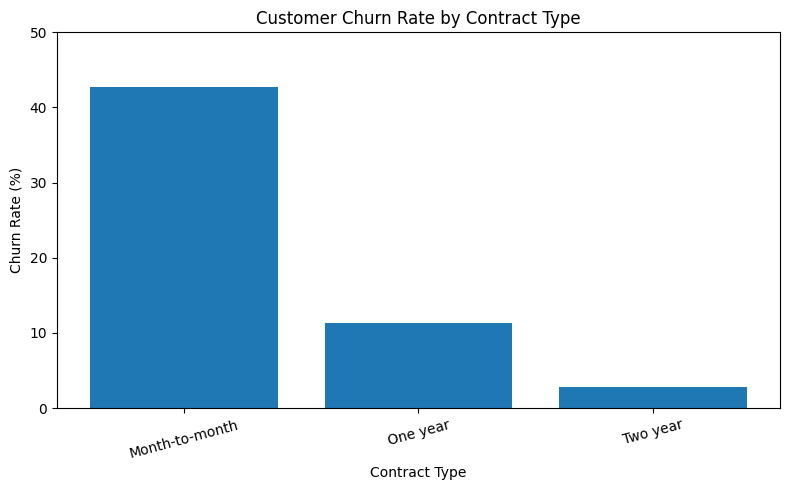

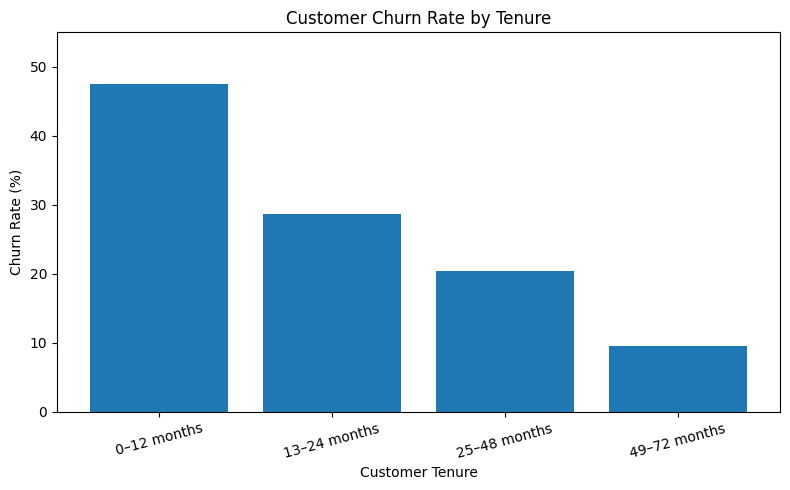

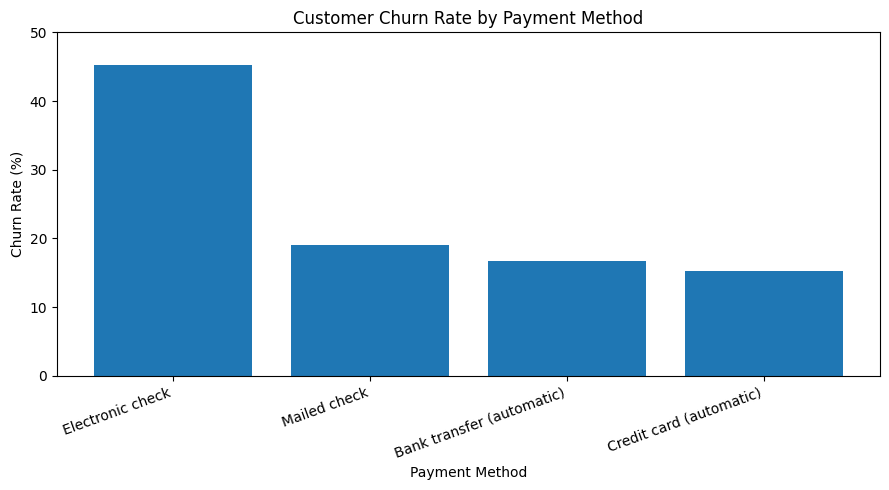

In [8]:
import matplotlib.pyplot as plt

# Chart 1: Churn rate by contract type
plt.figure(figsize=(8, 5))
plt.bar(
    contract_churn["Contract"],
    contract_churn["Churn_Rate_Percent"]
)
plt.title("Customer Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 50)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# Chart 2: Churn rate by tenure group
plt.figure(figsize=(8, 5))
plt.bar(
    tenure_churn["Tenure_Group"].astype(str),
    tenure_churn["Churn_Rate_Percent"]
)
plt.title("Customer Churn Rate by Tenure")
plt.xlabel("Customer Tenure")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 55)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# Chart 3: Churn rate by payment method
plt.figure(figsize=(9, 5))
plt.bar(
    payment_churn["PaymentMethod"],
    payment_churn["Churn_Rate_Percent"]
)
plt.title("Customer Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 50)
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

In [9]:
# Churn rate by Internet Service
internet_churn = (
    df_clean.groupby("InternetService")["Churn"]
    .apply(lambda x: x.eq("Yes").mean() * 100)
    .reset_index(name="Churn_Rate_Percent")
    .sort_values("Churn_Rate_Percent", ascending=False)
)

print("--- Churn Rate by Internet Service ---")
display(internet_churn.round(2))


# Churn rate by Tech Support
support_churn = (
    df_clean.groupby("TechSupport")["Churn"]
    .apply(lambda x: x.eq("Yes").mean() * 100)
    .reset_index(name="Churn_Rate_Percent")
    .sort_values("Churn_Rate_Percent", ascending=False)
)

print("--- Churn Rate by Tech Support ---")
display(support_churn.round(2))

--- Churn Rate by Internet Service ---


,InternetService,Churn_Rate_Percent
1,Fiber optic,41.89
0,DSL,18.96
2,No,7.40


--- Churn Rate by Tech Support ---


,TechSupport,Churn_Rate_Percent
0,No,41.64
2,Yes,15.17
1,No internet service,7.40


In [10]:
# Compare churned and retained customers
customer_comparison = (
    df_clean.groupby("Churn")[
        ["tenure", "MonthlyCharges", "TotalCharges"]
    ]
    .agg(["mean", "median"])
    .round(2)
)

display(customer_comparison)

tenure        MonthlyCharges        TotalCharges         
        mean median           mean median         mean   median
Churn                                                          
No     37.57   38.0          61.27  64.43      2549.91  1679.52
Yes    17.98   10.0          74.44  79.65      1531.80   703.55